<a href="https://colab.research.google.com/github/bestza01/DaTa-MiNiNg-/blob/main/%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [3]:
import numpy as np

water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2

q1 = np.percentile(water, 25)
q3 = np.percentile(water, 75)
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr
mask = (water < lo) | (water > hi)
print('Q1:',q1)
print(f'Q3:{q3} IQR: {iqr} Lower:{lo} Upper:{hi}')
print(water[mask])

Q1: 175.5
Q3:185.5 IQR: 10.0 Lower:160.5 Upper:200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [14]:
def iqr_outliers(x, k=1.5):
    x=np.array(x,float)
    q1,q3 = np.percentile(x,[25,75])
    iqr = q3 - q1
    lo = q1 - k * iqr
    hi = q3 + k * iqr
    mask=(x<lo)|(x>hi)
    return mask, lo, hi
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน
for k in [1.5, 3]:
    mask,lo,hi=iqr_outliers(sales,k)
    print(f'k={k} mask={mask.all()} lo={lo} hi={hi}')
# TODO 2.2

# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19,100],20)[0].any()
print('ผ่านทุก assert')

k=1.5 mask=False lo=38.375 hi=67.375
k=3 mask=False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

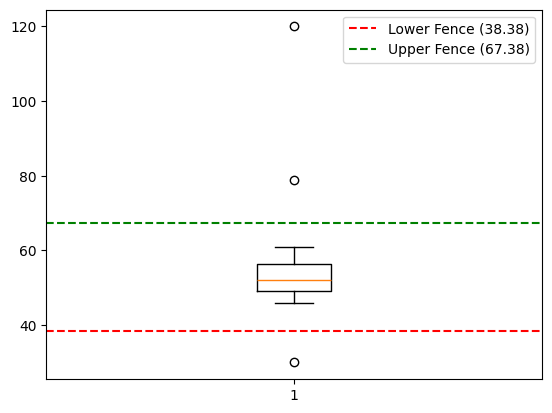

Lower whisker: 46.0 | Lower: 38.375
Upper whisker: 61.0 | Upper: 67.375
Fliers: [ 30. 120.  79.]
IQR outliers: [ 30. 120.  79.]


In [31]:
# TODO ข้อ 3
import matplotlib.pyplot as plt
import numpy as np
_, lower, upper = iqr_outliers(sales, k=1.5)

box = plt.boxplot(sales, whis=1.5)
plt.axhline(lower, color="red", linestyle="--", label=f"Lower Fence ({lower:.2f})")
plt.axhline(upper, color="green", linestyle="--", label=f"Upper Fence ({upper:.2f})")
plt.legend()
plt.show()

lower_whisker = min(box["whiskers"][0].get_ydata())
upper_whisker = max(box["whiskers"][1].get_ydata())
fliers = box["fliers"][0].get_ydata()

print("Lower whisker:", lower_whisker, "| Lower:", lower)
print("Upper whisker:", upper_whisker, "| Upper:", upper)
print("Fliers:", fliers)
print("IQR outliers:", fliers)

##ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน
ไม่จำเป็นต้องอยู่ที่รั้วพอดี
ปลายหนวดจะหยุดอยู่ที่ ค่าข้อมูลจริงที่อยู่ใกล้เคียงกับรั้วมากที่สุด

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [35]:
import pandas as pd
import numpy as np

wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# 4.1 ใช้ iqr_outliers กับค่าจ้างทั้ง 24 คนรวมกัน
mask_all, lo_all, hi_all = iqr_outliers(wage['wage_k'], k=1.5)
outliers_all = wage[mask_all]
print("=== 4.1 ภาพรวมทั้ง 24 คน ===")
print(f"รั้วล่างรวม: {lo_all:.2f} | รั้วบนรวม: {hi_all:.2f}")
print(f"พบ outlier ทั้งหมด {len(outliers_all)} คน ดังนี้:")
print(outliers_all)
print("-" * 50)

# 4.2–4.3 คำนวณรายกลุ่มอาชีพ
def get_group_stats(group):
    mask, lo, hi = iqr_outliers(group, k=1.5)
    return pd.Series({
        'Q1': np.percentile(group, 25),
        'Q3': np.percentile(group, 75),
        'IQR': np.percentile(group, 75) - np.percentile(group, 25),
        'Lower_Fence': lo,
        'Upper_Fence': hi
    })

stats_table = wage.groupby('occupation')['wage_k'].apply(get_group_stats).unstack()
print("=== 4.3 ตารางสรุปค่าสถิติรายกลุ่มอาชีพ ===")
print(stats_table)
print("-" * 50)

def mark_group_outliers(group):
    mask, _, _ = iqr_outliers(group, k=1.5)
    return mask

wage['is_outlier'] = wage.groupby('occupation')['wage_k'].transform(mark_group_outliers).astype(bool)
outliers_by_group = wage[wage['is_outlier']]

print("=== 4.2 พบ outlier รายกลุ่มอาชีพ ===")
print(outliers_by_group[['occupation', 'wage_k']])

=== 4.1 ภาพรวมทั้ง 24 คน ===
รั้วล่างรวม: -56.00 | รั้วบนรวม: 130.00
พบ outlier ทั้งหมด 0 คน ดังนี้:
Empty DataFrame
Columns: [occupation, wage_k]
Index: []
--------------------------------------------------
=== 4.3 ตารางสรุปค่าสถิติรายกลุ่มอาชีพ ===
               Q1     Q3   IQR  Lower_Fence  Upper_Fence
occupation                                              
cleaner     12.00  14.25  2.25        8.625       17.625
clerk       18.75  21.25  2.50       15.000       25.000
engineer    60.75  65.25  4.50       54.000       72.000
--------------------------------------------------
=== 4.2 พบ outlier รายกลุ่มอาชีพ ===
   occupation  wage_k
7     cleaner      35
15      clerk       9


ผลรวม : ไม่พบ Outlier เพราะพอเอาทุกอาชีพมารวมกัน เงินเดือนที่สูงมากของกลุ่มวิศวกรดึงให้รั้วเบ้กว้างขึ้นจนกวาดข้อมูลทุกอย่างให้ดูเป็นปกติ




ผลรายกลุ่ม : พบ Outlier เพราะเปรียบเทียบภายใต้บริบทเดียวกันทำให้สะท้อนค่าสถิติที่แท้จริงของกลุ่มนั้นและตรวจพบคนที่ได้เงินเดือนสูงต่ำผิดปกติในอาชีพตัวเองได้